<a href="https://colab.research.google.com/github/Muhammadelzmrany/Word2Vec-GloVe-NLP-Comparison-4/blob/main/Word2Vec_Skip_gram_and_GloVe_using_a_document_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Word Embeddings Comparison

Compare Word2Vec Skip-gram and GloVe using a document classification dataset.

## 1. Load and Inspect the Dataset

Load the CSV file and inspect its columns, missing values, and duplicate rows before preprocessing.

In [ ]:
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split

DATA_PATH = "/content/df_file.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.2

In [ ]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

Shape: (2225, 2)


,Text,Label
0,Budget to set scene for election\n \n Gordon B...,0
1,Army chiefs in regiments decision\n \n Militar...,0
2,Howard denies split over ID cards\n \n Michael...,0
3,Observers to monitor UK election\n \n Minister...,0
4,Kilroy names election seat target\n \n Ex-chat...,0


In [ ]:
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    2225 non-null   object
 1   Label   2225 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 34.9+ KB

Missing values:
Text     0
Label    0
dtype: int64

Duplicate rows: 98


## 2. Prepare the Data
Remove missing and duplicate documents, then give each numeric label a topic name.
The label meanings below were inferred from the article samples.

In [ ]:
label_names = {
    0: "politics",
    1: "sport",
    2: "tech",
    3: "entertainment",
    4: "business"
}

df = df.dropna(subset=["Text", "Label"]).copy()
df["Text"] = df["Text"].str.strip()
df = df[df["Text"] != ""]

assert df["Label"].isin(label_names).all(), "Unexpected label found."
assert df.groupby("Text")["Label"].nunique().max() == 1, "Conflicting labels."

df = df.drop_duplicates(subset="Text").reset_index(drop=True)
df["Topic"] = df["Label"].map(label_names)

print("Documents:", len(df))
display(df["Topic"].value_counts())

Documents: 2127


,count
Topic,
sport,505
business,503
politics,403
entertainment,369
tech,347


In [ ]:
# Show one short example from each topic.
examples = df.groupby("Topic").head(1)[["Topic", "Text"]].copy()
examples["Text"] = examples["Text"].str[:200]

display(examples)

,Topic,Text
0,politics,Budget to set scene for election\n \n Gordon B...
403,sport,Hodges announces rugby retirement\n \n Scarlet...
908,tech,Digital UK driven by net and TV\n \n The UK's ...
1255,entertainment,Super Size Me wins writers' award\n \n Super S...
1624,business,US consumer confidence up\n \n Consumers' conf...


## 3. Clean the Text
Lowercase the text, keep English words, remove stop words, and apply lemmatization.
Keep no, not, and nor because they express negation.

We use WordNet's default noun lemmatization. It simplifies words such as
"cars" to "car", but does not normalize every verb form.

In [ ]:
nltk.download("stopwords", quiet=True, raise_on_error=True)
nltk.download("wordnet", quiet=True, raise_on_error=True)

stop_words = set(stopwords.words("english")) - {"no", "not", "nor"}
lemmatizer = WordNetLemmatizer()

In [ ]:
def clean_text(text):
    text = text.lower().replace("’", "'")

    # Keep negation before removing punctuation.
    text = text.replace("can't", "can not")
    text = text.replace("won't", "will not")
    text = text.replace("n't", " not")

    words = re.findall(r"[a-z]+", text)
    words = [word for word in words if word not in stop_words]
    words = [lemmatizer.lemmatize(word) for word in words]

    return words

In [ ]:
df["Tokens"] = df["Text"].apply(clean_text)
df["Clean_Text"] = df["Tokens"].apply(" ".join)

print("Empty texts:", df["Clean_Text"].eq("").sum())
df = df[df["Clean_Text"] != ""].copy()

assert df.groupby("Clean_Text")["Label"].nunique().max() == 1, "Conflicting labels after cleaning."

print("Cleaned duplicates:", df["Clean_Text"].duplicated().sum())
df = df.drop_duplicates(subset="Clean_Text").reset_index(drop=True)

print("Documents after cleaning:", len(df))

Empty texts: 0
Cleaned duplicates: 10
Documents after cleaning: 2117


In [ ]:
print("Before cleaning:\n")
print(df.loc[0, "Text"][:500])

print("\nAfter cleaning:\n")
print(df.loc[0, "Clean_Text"][:500])

Before cleaning:

Budget to set scene for election
 
 Gordon Brown will seek to put the economy at the centre of Labour's bid for a third term in power when he delivers his ninth Budget at 1230 GMT. He is expected to stress the importance of continued economic stability, with low unemployment and interest rates. The chancellor is expected to freeze petrol duty and raise the stamp duty threshold from Â£60,000. But the Conservatives and Lib Dems insist voters face higher taxes and more means-testing under Labour.
 

After cleaning:

budget set scene election gordon brown seek put economy centre labour bid third term power delivers ninth budget gmt expected stress importance continued economic stability low unemployment interest rate chancellor expected freeze petrol duty raise stamp duty threshold conservative lib dems insist voter face higher tax mean testing labour treasury official said not pre election giveaway mr brown thought bn spare increase stamp duty threshold freeze petrol dut

## 4. Split the Data
Use 80% for training and 20% for testing.
Stratification keeps similar topic proportions in both sets.

Word2Vec will learn only from the training documents.

In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df["Topic"],
    random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training documents:", len(train_df))
print("Testing documents:", len(test_df))

Training documents: 1693
Testing documents: 424


In [ ]:
split_counts = pd.DataFrame({
    "Train": train_df["Topic"].value_counts(),
    "Test": test_df["Topic"].value_counts()
})

display(split_counts)

# Check that duplicate documents do not cross the split.
assert set(train_df["Clean_Text"]).isdisjoint(test_df["Clean_Text"])

,Train,Test
Topic,,
business,401,101
entertainment,295,74
politics,322,81
sport,401,100
tech,274,68


## 5. Train Word2Vec Skip-gram

Train Word2Vec using only the training documents.

Skip-gram predicts surrounding words from a center word.
We use 100-dimensional vectors, a context window of 5, and 20 epochs.
Words appearing fewer than twice are ignored.

Using one worker and a fixed seed reduces variation between runs.

In [ ]:
from gensim.models import Word2Vec

w2v_model = Word2Vec(
    sentences=train_df["Tokens"].tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=20,
    workers=1,
    seed=RANDOM_STATE
)

print("Vocabulary size:", len(w2v_model.wv))
print("Vector size:", w2v_model.wv.vector_size)

Vocabulary size: 14490
Vector size: 100


## 6. Check Word2Vec Coverage

Measure how many unique words in each split have a learned vector.
Words outside the model vocabulary are called out-of-vocabulary (OOV) words.

In [ ]:
coverage = []

for split, frame in [("Train", train_df), ("Test", test_df)]:
    words = set(word for tokens in frame["Tokens"] for word in tokens)
    known_words = [word for word in words if word in w2v_model.wv]

    coverage.append({
        "Split": split,
        "Unique words": len(words),
        "Known words": len(known_words),
        "OOV words": len(words) - len(known_words),
        "Coverage (%)": round(len(known_words) / len(words) * 100, 2)
    })

display(pd.DataFrame(coverage))

,Split,Unique words,Known words,OOV words,Coverage (%)
0,Train,22567,14490,8077,64.21
1,Test,11785,8449,3336,71.69


## 7. Inspect Similar Words

Select the most frequent training word in the model vocabulary.
Display its five nearest neighbors using cosine similarity.

These neighbors show learned associations, not necessarily synonyms.
The comparison with GloVe will use words shared by both models.

In [ ]:
from collections import Counter

word_counts = Counter(
    word for tokens in train_df["Tokens"] for word in tokens
)

word = next(
    word for word, count in word_counts.most_common()
    if word in w2v_model.wv
)

similar_words = w2v_model.wv.most_similar(word, topn=5)

print("Selected word:", word)

display(pd.DataFrame(
    similar_words,
    columns=["Similar word", "Cosine similarity"]
))

Selected word: said


,Similar word,Cosine similarity
0,tyler,0.659449
1,fiona,0.655202
2,plausible,0.648465
3,dishonest,0.646521
4,cock,0.643539


## 8. Load GloVe

Load the pretrained glove-wiki-gigaword-100 model.
It contains 100-dimensional word vectors.

Word2Vec learned from our training documents, while GloVe learned from
a larger external corpus. This difference matters when comparing results.

The first download requires internet access and may take several minutes.
A local extracted GloVe text file can also be used.

In [ ]:
import gensim.downloader as api
from gensim.models import KeyedVectors

# Leave as None to download, or enter a local GloVe text file path.
GLOVE_PATH = None

if GLOVE_PATH is None:
    glove_model = api.load("glove-wiki-gigaword-100")
else:
    glove_model = KeyedVectors.load_word2vec_format(
        GLOVE_PATH,
        binary=False,
        no_header=True
    )

assert glove_model.vector_size == 100, "Use 100-dimensional GloVe vectors."

print("Vocabulary size:", len(glove_model))
print("Vector size:", glove_model.vector_size)

[==================================================] 100.0% 128.1/128.1MB downloaded
Vocabulary size: 400000
Vector size: 100


## 9. Compare Vocabulary Coverage

Calculate unique-word coverage for both models using the same documents.
This measures vocabulary availability, not semantic quality.

In [ ]:
models = {
    "Word2Vec": w2v_model.wv,
    "GloVe": glove_model
}

coverage = []

for split, frame in [("Train", train_df), ("Test", test_df)]:
    words = set(word for tokens in frame["Tokens"] for word in tokens)

    for name, model in models.items():
        known_words = [word for word in words if word in model]

        coverage.append({
            "Model": name,
            "Split": split,
            "Unique words": len(words),
            "Known words": len(known_words),
            "OOV words": len(words) - len(known_words),
            "Coverage (%)": round(len(known_words) / len(words) * 100, 2)
        })

coverage_df = pd.DataFrame(coverage)
display(coverage_df)

,Model,Split,Unique words,Known words,OOV words,Coverage (%)
0,Word2Vec,Train,22567,14490,8077,64.21
1,GloVe,Train,22567,21790,777,96.56
2,Word2Vec,Test,11785,8449,3336,71.69
3,GloVe,Test,11785,11533,252,97.86


## 10. Check GloVe Neighbors

Inspect GloVe's neighbors for the same word used in the Word2Vec check.
Each model searches its own vocabulary in this initial check.

Later, the direct comparison will use a shared candidate vocabulary.

In [ ]:
# Reuse the word selected in Cell 22.
print("Selected word:", word)

if word in glove_model:
    similar_words = glove_model.most_similar(word, topn=5)

    display(pd.DataFrame(
        similar_words,
        columns=["Similar word", "Cosine similarity"]
    ))
else:
    print("This word is not in the GloVe vocabulary.")

Selected word: said


,Similar word,Cosine similarity
0,told,0.848746
1,says,0.816152
2,saying,0.788759
3,added,0.782623
4,asked,0.776341


## 11. Select Topic Words

Use average TF-IDF scores to select five representative words for each topic.
Select words from training documents only, and keep words available in both models.

TF-IDF is used only for word selection, not as a replacement for word embeddings.
Assign each selected word to one topic to keep the later plots readable.

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

tfidf_matrix = tfidf.fit_transform(train_df["Clean_Text"])
vocabulary = tfidf.get_feature_names_out()

shared_words = [
    word for word in vocabulary
    if word in w2v_model.wv and word in glove_model
]

shared_set = set(shared_words)

print("Shared training vocabulary:", len(shared_words))

Shared training vocabulary: 14275


In [ ]:
# Exclude general words and short abbreviations from topic selection only.
general_words = {
    "said", "say", "not", "no", "nor",
    "mr", "mrs", "ms", "people", "also",
    "one", "would", "could", "year", "new"
}

topic_words = {}
used_words = set()

for topic in label_names.values():
    topic_rows = train_df["Topic"].eq(topic).to_numpy()
    scores = np.asarray(tfidf_matrix[topic_rows].mean(axis=0)).ravel()
    ranked_indices = np.argsort(-scores, kind="stable")

    selected = []

    for index in ranked_indices:
        word = vocabulary[index]

        if (
            scores[index] > 0
            and word in shared_set
            and word not in general_words
            and word not in used_words
            and len(word) > 2
        ):
            selected.append(word)
            used_words.add(word)

        if len(selected) == 5:
            break

    topic_words[topic] = selected

    if len(selected) < 5:
        print(f"Only {len(selected)} shared words found for {topic}.")

display(pd.DataFrame({
    topic: pd.Series(words)
    for topic, words in topic_words.items()
}))

,politics,sport,tech,entertainment,business
0,labour,game,mobile,film,bank
1,election,england,technology,award,company
2,party,player,phone,best,market
3,blair,win,computer,music,firm
4,tory,match,user,show,growth


## 12. Compare Word Relationships

Use the first selected word from each topic as an anchor.
Find its five nearest neighbors in each model using cosine similarity.

Both models search the same shared training vocabulary.
Exclude the anchor itself from the results.

Similar words may be synonyms, related concepts, or words used in similar contexts.
A higher cosine score alone does not prove better semantic quality.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

neighbor_rows = []

for name, model in models.items():
    candidate_vectors = model[shared_words]

    for topic, words in topic_words.items():
        if not words:
            print("Skipping topic with no shared words:", topic)
            continue

        anchor = words[0]

        if anchor not in model:
            print("Skipping missing word:", anchor)
            continue

        scores = cosine_similarity(
            model[anchor].reshape(1, -1),
            candidate_vectors
        )[0]

        ranked_indices = np.argsort(-scores)
        nearest = [
            index for index in ranked_indices
            if shared_words[index] != anchor
        ][:5]

        for rank, index in enumerate(nearest, start=1):
            neighbor_rows.append({
                "Topic": topic,
                "Anchor": anchor,
                "Rank": rank,
                "Model": name,
                "Neighbor": shared_words[index],
                "Cosine": float(scores[index])
            })

neighbors_df = pd.DataFrame(neighbor_rows)

In [ ]:
comparison = neighbors_df.pivot(
    index=["Topic", "Anchor", "Rank"],
    columns="Model",
    values=["Neighbor", "Cosine"]
)

display(comparison.round(3))

Neighbor                   Cosine          
Model                              GloVe       Word2Vec     GloVe  Word2Vec
Topic         Anchor Rank                                                  
business      bank   1           banking          caire  0.753071  0.732986
                     2            credit     alexandria   0.70376  0.724414
                     3        investment         banque  0.693994  0.714116
                     4         financial       governor  0.677741  0.648567
                     5           lending           icbc  0.664503  0.640576
entertainment film   1             movie          movie  0.905512  0.654271
                     2          directed         cinema  0.812436  0.644163
                     3       documentary    blockbuster  0.807579  0.631001
                     4             drama      hollywood  0.792917   0.61923
                     5            comedy    documentary  0.784275  0.612248
politics      labour 1             labor           tory  0.852207  0.746985
                     2        opposition          party  0.692071  0.714775
                     3             party   conservative  0.684881  0.702801
                     4           liberal       election  0.672826  0.676975
                     5     parliamentary     electorate  0.647529  0.643827
sport         game   1              play        console  0.831627  0.583972
                     2            season       rockstar  0.773319  0.556428
                     3            player         gaming  0.757982  0.554609
                     4             match           halo  0.728291  0.549232
                     5           scoring           espn  0.720136  0.548854
tech          mobile 1          wireless          phone  0.833474  0.808956
                     2             phone           gprs  0.730746  0.698948
                     3          internet  reconditioned  0.713131  0.692693
                     4         broadband        handset   0.71067  0.691487
                     5           digital           have  0.665092  0.678201

## 13. Word Relationship Observations

For "bank", GloVe returns financial terms such as "banking", "credit",
and "investment". Word2Vec returns a different set, including "banque"
and "governor", which may reflect the training articles.

Both models identify "movie" as the closest word to "film".

For "labour", GloVe returns the spelling variant "labor", while Word2Vec
returns the politically related word "tory".

These examples show different learned associations. They do not establish
an overall winner, especially because the models use different training corpora.

## 14. Prepare Words for Visualization

Use the same selected words in both models.
Each color represents the topic used to select the word.

Normalize the vectors before projection so that vector length does not
dominate the comparison.

In [ ]:
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

plot_words = []
plot_topics = []

for topic, words in topic_words.items():
    for word in words:
        plot_words.append(word)
        plot_topics.append(topic)

assert len(plot_words) >= 3, "Select at least three shared words."

plot_vectors = {
    name: normalize(model[plot_words])
    for name, model in models.items()
}

print("Number of words:", len(plot_words))

display(pd.DataFrame({
    "Word": plot_words,
    "Topic": plot_topics
}))

Number of words: 25


,Word,Topic
0,labour,politics
1,election,politics
2,party,politics
3,blair,politics
4,tory,politics
5,game,sport
6,england,sport
7,player,sport
8,win,sport
9,match,sport


In [ ]:
topic_colors = {
    "politics": "tab:blue",
    "sport": "tab:orange",
    "tech": "tab:green",
    "entertainment": "tab:red",
    "business": "tab:purple"
}

def plot_embeddings(points, title, method):
    plt.figure(figsize=(11, 7))

    for topic, color in topic_colors.items():
        indices = [
            i for i, label in enumerate(plot_topics)
            if label == topic
        ]

        if indices:
            plt.scatter(
                points[indices, 0],
                points[indices, 1],
                color=color,
                label=topic
            )

    for i, word in enumerate(plot_words):
        plt.annotate(
            word,
            (points[i, 0], points[i, 1]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=9
        )

    plt.title(title)
    plt.xlabel(f"{method} dimension 1")
    plt.ylabel(f"{method} dimension 2")
    plt.legend(title="Topic")
    plt.tight_layout()
    plt.show()

## 15. PCA Visualization

PCA is a linear method that projects vectors onto directions with the most variance.
We reduce the 100-dimensional vectors to two dimensions.

The explained variance shows how much variation these two dimensions retain.
Some relationships may be lost in this projection.

Word2Vec explained variance: 25.19%


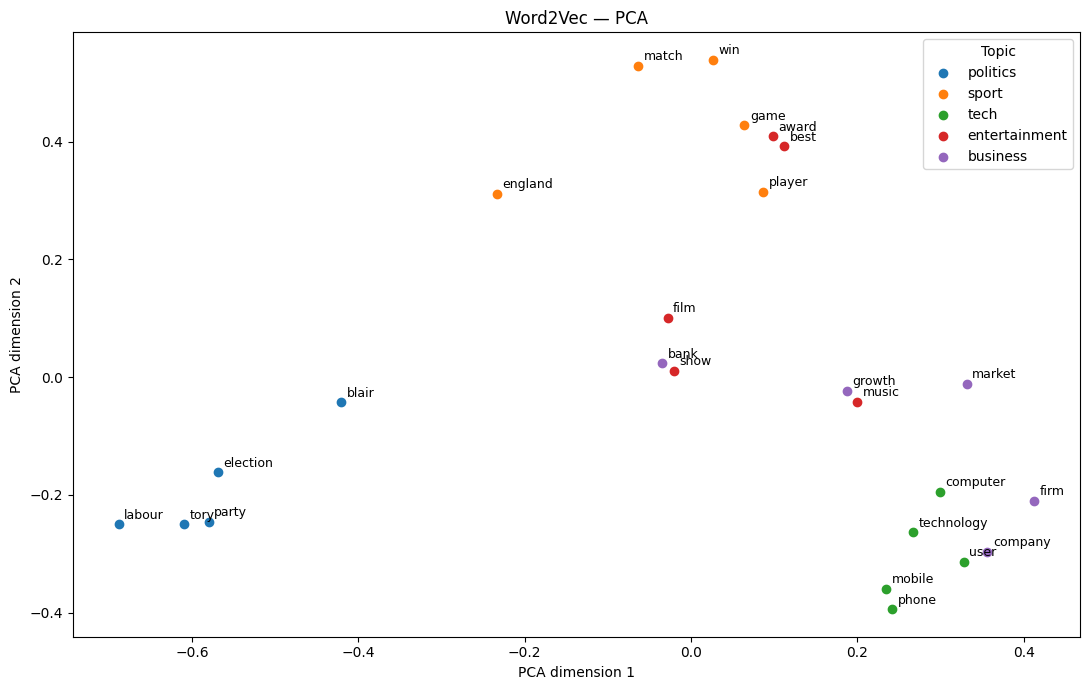

GloVe explained variance: 35.17%


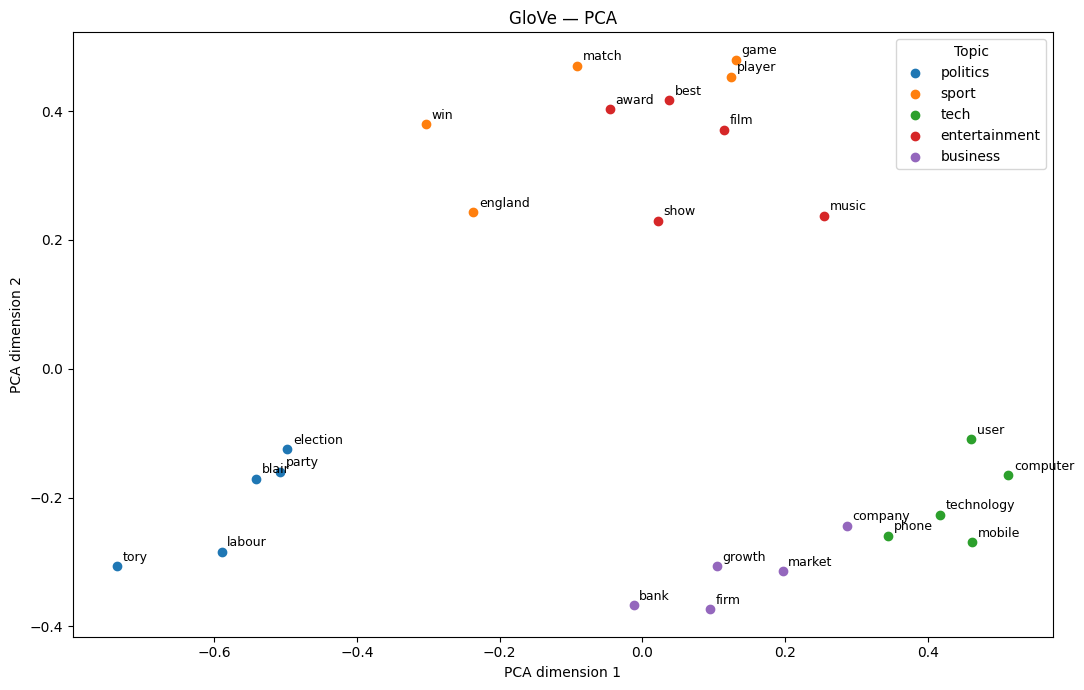

In [ ]:
pca_points = {}
pca_variance = {}

for name, vectors in plot_vectors.items():
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    points = pca.fit_transform(vectors)

    pca_points[name] = points
    pca_variance[name] = pca.explained_variance_ratio_.sum()

    print(f"{name} explained variance: {pca_variance[name]:.2%}")
    plot_embeddings(points, f"{name} — PCA", "PCA")

## 16. t-SNE Visualization

t-SNE is a nonlinear method that emphasizes local neighborhoods.
Unlike PCA, it does not aim to preserve the largest amount of variance.

Use the same settings and word list for both models.
Keep perplexity below the number of words.

Cluster sizes, distances between distant groups, and axis directions should
not be treated as semantic measurements. These plots are exploratory and
cannot prove semantic similarity on their own.

Perplexity: 5


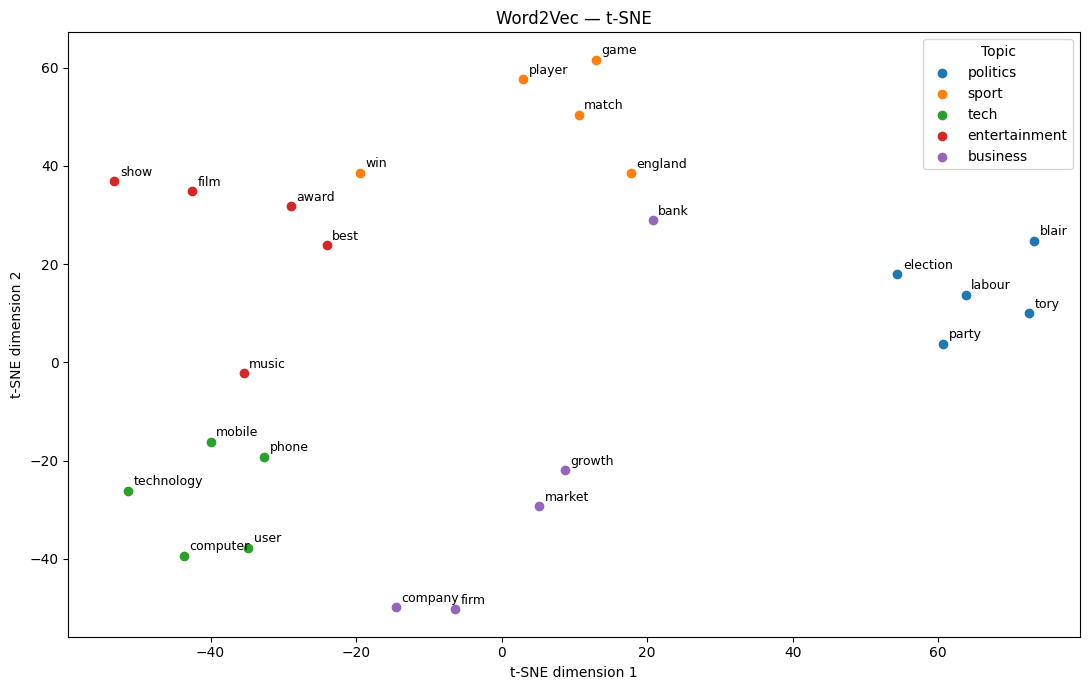

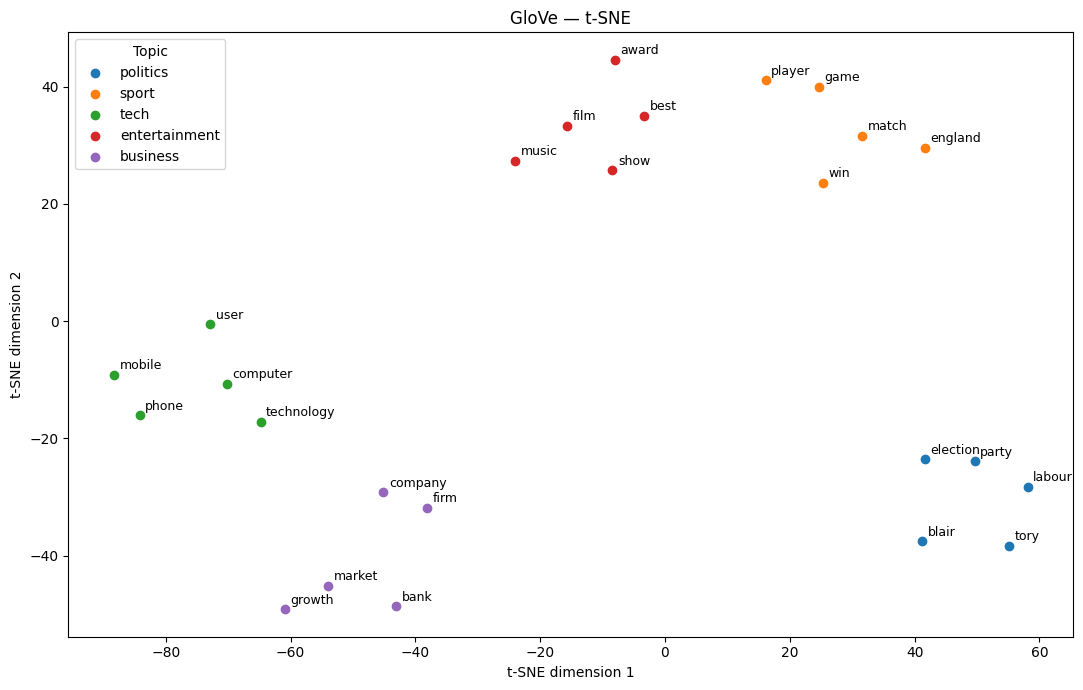

In [ ]:
perplexity = min(5, max(1, (len(plot_words) - 1) / 3))
tsne_points = {}

print("Perplexity:", perplexity)

for name, vectors in plot_vectors.items():
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="random",
        learning_rate="auto",
        random_state=RANDOM_STATE
    )

    points = tsne.fit_transform(vectors)
    tsne_points[name] = points

    plot_embeddings(points, f"{name} — t-SNE", "t-SNE")

## 17. Topic Coherence

Compare the average cosine similarity between words from the same topic
with the average similarity between words from different topics.

A positive gap means that the selected words are more similar within
their topic than across topics.

This is a simple embedding-based coherence measure, not a standard
corpus-based coherence score. Results depend on the selected words.

In [ ]:
from itertools import combinations

coherence_rows = []

for name, model in models.items():
    for topic, words in topic_words.items():
        other_words = [
            word
            for other_topic, group in topic_words.items()
            if other_topic != topic
            for word in group
        ]

        if len(words) < 2 or not other_words:
            print("Skipping topic with too few words:", topic)
            continue

        within_scores = [
            model.similarity(word1, word2)
            for word1, word2 in combinations(words, 2)
        ]

        between_scores = cosine_similarity(
            model[words],
            model[other_words]
        )

        within = np.mean(within_scores)
        between = between_scores.mean()

        coherence_rows.append({
            "Model": name,
            "Topic": topic,
            "Within topic": within,
            "Between topics": between,
            "Gap": within - between
        })

coherence_df = pd.DataFrame(coherence_rows)
display(coherence_df.round(3))

,Model,Topic,Within topic,Between topics,Gap
0,Word2Vec,politics,0.579,0.162,0.417
1,Word2Vec,sport,0.344,0.163,0.182
2,Word2Vec,tech,0.449,0.197,0.251
3,Word2Vec,entertainment,0.281,0.176,0.105
4,Word2Vec,business,0.342,0.176,0.166
5,GloVe,politics,0.558,0.220,0.338
6,GloVe,sport,0.631,0.314,0.317
7,GloVe,tech,0.612,0.287,0.325
8,GloVe,entertainment,0.614,0.326,0.288
9,GloVe,business,0.582,0.323,0.259


,Within topic,Between topics,Gap
Model,,,
GloVe,0.600,0.294,0.306
Word2Vec,0.399,0.175,0.224


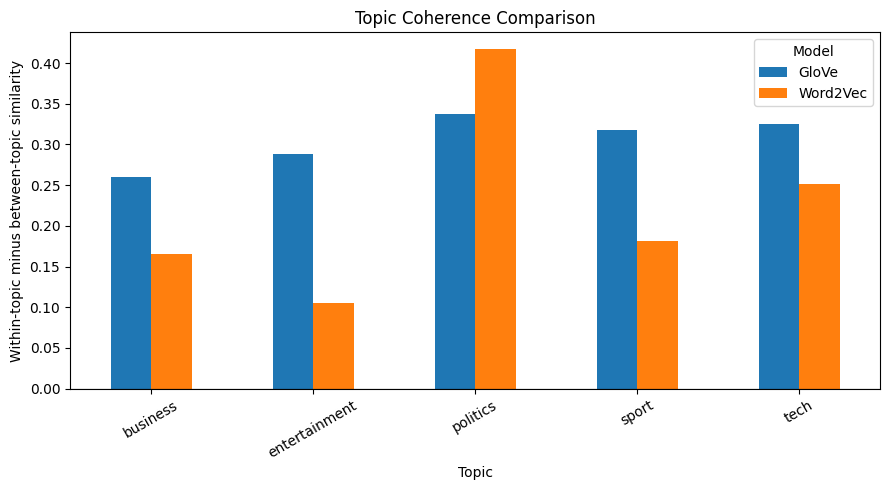

In [ ]:
coherence_summary = coherence_df.groupby("Model")[
    ["Within topic", "Between topics", "Gap"]
].mean()

display(coherence_summary.round(3))

coherence_df.pivot(
    index="Topic",
    columns="Model",
    values="Gap"
).plot(kind="bar", figsize=(9, 5))

plt.title("Topic Coherence Comparison")
plt.xlabel("Topic")
plt.ylabel("Within-topic minus between-topic similarity")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 18. Create Document Vectors

Represent each document by the average of its word vectors.
Ignore words that are outside the model vocabulary.

If a document has no known words, use a zero vector and count it.
Keep these documents in the evaluation.

Mean pooling is simple, but it loses word order and may weaken negation.

In [ ]:
def get_document_vectors(documents, model):
    document_vectors = []
    empty_count = 0

    for tokens in documents:
        known_words = [word for word in tokens if word in model]

        if known_words:
            vector = model[known_words].mean(axis=0)
        else:
            vector = np.zeros(model.vector_size)
            empty_count += 1

        document_vectors.append(vector)

    return np.array(document_vectors), empty_count

In [ ]:
document_data = {}
empty_rows = []

for name, model in models.items():
    X_train, empty_train = get_document_vectors(
        train_df["Tokens"], model
    )

    X_test, empty_test = get_document_vectors(
        test_df["Tokens"], model
    )

    assert empty_train < len(train_df), "All training documents are OOV."
    assert np.isfinite(X_train).all(), "Invalid training vectors."
    assert np.isfinite(X_test).all(), "Invalid test vectors."

    document_data[name] = {
        "train": X_train,
        "test": X_test
    }

    empty_rows.append({
        "Model": name,
        "Zero-vector train documents": empty_train,
        "Zero-vector test documents": empty_test
    })

    print(name)
    print("Training shape:", X_train.shape)
    print("Testing shape:", X_test.shape)
    print()

empty_df = pd.DataFrame(empty_rows)
display(empty_df)

Word2Vec
Training shape: (1693, 100)
Testing shape: (424, 100)

GloVe
Training shape: (1693, 100)
Testing shape: (424, 100)



,Model,Zero-vector train documents,Zero-vector test documents
0,Word2Vec,0,0
1,GloVe,0,0


## 19. Document Classification

Train Logistic Regression on the document vectors.

Use the same train/test split and classifier settings for both models.
Standardize the features using training data only.

Evaluate with:
- Accuracy: the proportion of correctly classified documents.
- Macro-F1: the average F1 score across topics, giving each topic equal weight.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_train = train_df["Topic"]
y_test = test_df["Topic"]

classifiers = {}
predictions = {}
result_rows = []

for name, vectors in document_data.items():
    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )

    classifier.fit(vectors["train"], y_train)
    predicted = classifier.predict(vectors["test"])

    classifiers[name] = classifier
    predictions[name] = predicted

    result_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Macro-F1": f1_score(
            y_test,
            predicted,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(result_rows)
display(results_df.round(4))

,Model,Accuracy,Macro-F1
0,Word2Vec,0.9693,0.9697
1,GloVe,0.9693,0.9683


In [ ]:
topics = list(label_names.values())

for name, predicted in predictions.items():
    print(name)
    print(
        classification_report(
            y_test,
            predicted,
            labels=topics,
            digits=3,
            zero_division=0
        )
    )

Word2Vec
               precision    recall  f1-score   support

     politics      0.963     0.951     0.957        81
        sport      1.000     0.990     0.995       100
         tech      0.984     0.926     0.955        68
entertainment      1.000     1.000     1.000        74
     business      0.916     0.970     0.942       101

     accuracy                          0.969       424
    macro avg      0.973     0.967     0.970       424
 weighted avg      0.970     0.969     0.969       424

GloVe
               precision    recall  f1-score   support

     politics      0.952     0.988     0.970        81
        sport      1.000     0.980     0.990       100
         tech      0.969     0.912     0.939        68
entertainment      0.986     0.986     0.986        74
     business      0.942     0.970     0.956       101

     accuracy                          0.969       424
    macro avg      0.970     0.967     0.968       424
 weighted avg      0.970     0.969     0.969 

## 20. Confusion Matrices

Rows show the actual topics, and columns show the predicted topics.
Values on the diagonal are correct predictions.
Values outside the diagonal show classification errors.

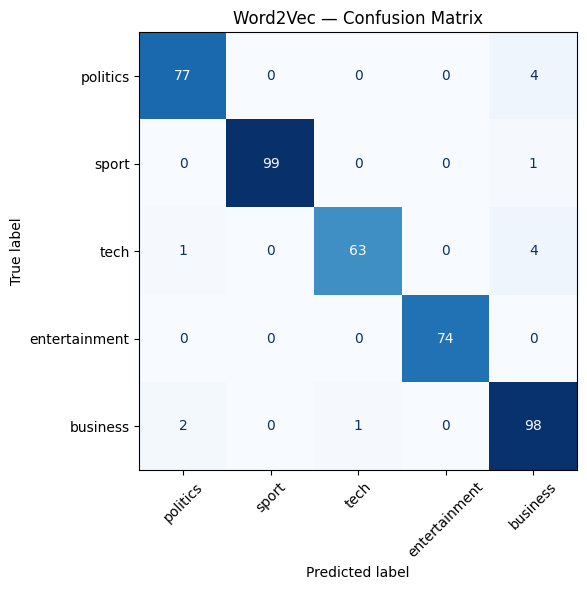

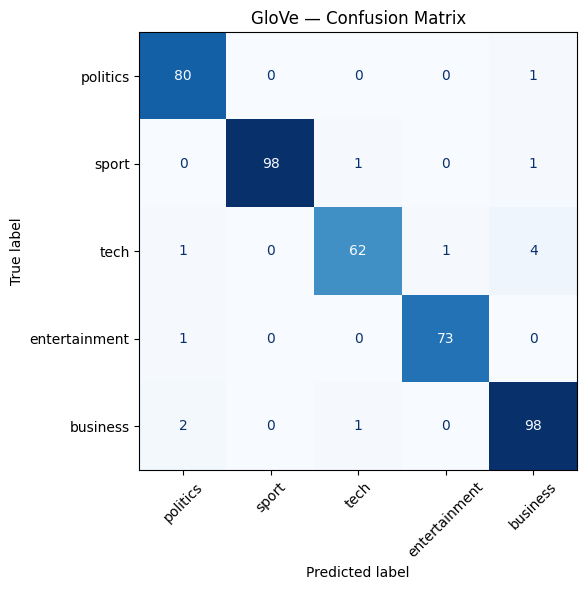

In [ ]:
for name, predicted in predictions.items():
    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted,
        labels=topics,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

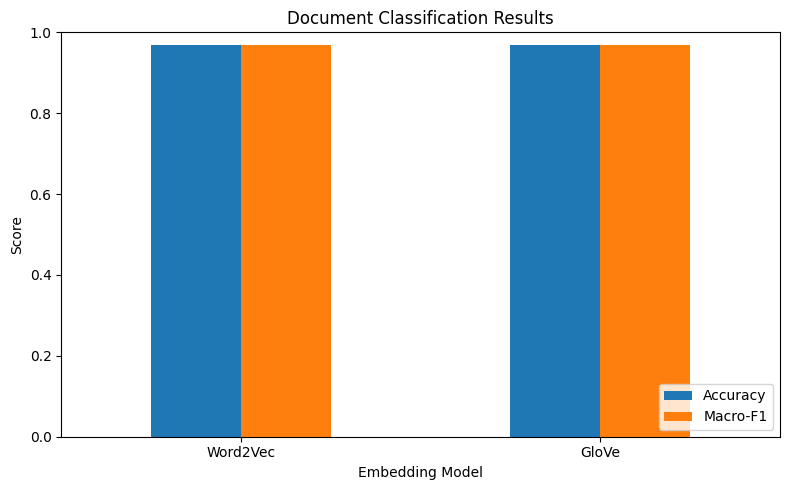

In [ ]:
results_df.set_index("Model")[["Accuracy", "Macro-F1"]].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1)
)

plt.title("Document Classification Results")
plt.xlabel("Embedding Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 21. Results and Discussion

The following summary uses the results calculated in this notebook.

Classification measures performance on unseen documents.
The coherence gap describes the selected topic words.
Neither measure alone establishes which model is universally better.

Nearest-neighbor examples provide qualitative semantic evidence.
Without a human-rated similarity benchmark, cosine scores should not be
reported as semantic accuracy.

In [ ]:
for metric in ["Accuracy", "Macro-F1"]:
    best_score = results_df[metric].max()

    winners = results_df.loc[
        np.isclose(
            results_df[metric],
            best_score,
            rtol=0,
            atol=1e-12
        ),
        "Model"
    ].tolist()

    if len(winners) == 1:
        print(f"{winners[0]} achieved the higher {metric}: {best_score:.4f}")
    else:
        print(f"The models tied on {metric}: {best_score:.4f}")

print("\nMean topic coherence gap:")
for name, row in coherence_summary.iterrows():
    print(f"{name}: {row['Gap']:.4f}")

print("\nTest vocabulary coverage:")
display(
    coverage_df.loc[
        coverage_df["Split"] == "Test",
        ["Model", "Known words", "OOV words", "Coverage (%)"]
    ]
)

print("\nVariance retained by the two PCA components:")
for name, variance in pca_variance.items():
    print(f"{name}: {variance:.2%}")

The models tied on Accuracy: 0.9693
Word2Vec achieved the higher Macro-F1: 0.9697

Mean topic coherence gap:
GloVe: 0.3056
Word2Vec: 0.2242

Test vocabulary coverage:


,Model,Known words,OOV words,Coverage (%)
2,Word2Vec,8449,3336,71.69
3,GloVe,11533,252,97.86



Variance retained by the two PCA components:
Word2Vec: 25.19%
GloVe: 35.17%


## 22. Limitations and Conclusion

Word2Vec was trained on this dataset's training documents, while GloVe
was pretrained on a larger external corpus. Their comparison therefore
reflects differences in both training data and embedding methods.

Other limitations include:
- A single train/test split.
- Out-of-vocabulary words.
- Basic noun lemmatization.
- Loss of word order when averaging word vectors.
- A small, selected vocabulary for coherence and visualization.
- Sensitivity of t-SNE to its settings and the selected words.

PCA and t-SNE are exploratory visualizations. Visual separation does not
prove semantic quality, and a higher PCA explained variance does not
necessarily indicate a better embedding model.

The printed results identify the stronger classifier for this experiment.
The neighbor examples and coherence scores provide additional evidence,
but they do not establish a universal winner.